**Are Large Language Models Sensitive to Omission vs Commission in Moral Evaluation?**

Tests whether LLMs exhibit human-like omission bias using surprisal as a measure of implicit moral expectation across four autoregressive language models and four stimulus conditions.

**Key finding:** LLMs show a reversed omission pattern, where moral disapproval is more expected following omissions than commissions, which suggests statistical language patterns rather than human-like moral reasoning.

**Environment:** Runs locally or on Colab (no GPU required)  

**Introduction**

In human moral psychology, omission bias means that people judge harmful actions, called commissions, as more morally wrong than equally harmful failures to act, called omissions. This phenomenon has been documented across medical, legal, and public policy domains and was first widely popularized by Spranca et al. (1991), with many subsequent replications including Baron & Ritov (2004) and Jamison et al. (2020). In these studies, both commission and omission lead to equal levels of harm, yet people consistently judge commissions as more wrong.

For this study, I was curious about whether large language models exhibit a similar sensitivity to omission versus commission when making moral predictions in language. Rather than asking models for explicit moral judgments, I operationalize moral expectation using surprisal to see how expected a word is in context. Specifically, I test whether the surprisal of the moral evaluation word “wrong” differs systematically following commission versus omission scenarios. If LLMs mirror the human omission bias, “wrong” should be more expected and have a lower surprisal following commissions than omissions.


**Methods**

Omission bias is defined as an unequal moral evaluation between harmful actions and harmful inactions. I operationalized this by measuring the difference in surprisal for moral evaluation words “wrong” and “acceptable” following  matched commission and omission scenarios. This measure attempts to evaluate the models’ moral expectations in language, rather than explicit moral judgments or real-world behavior.

Four stimulus conditions were constructed using 14 commission–omission minimal pairs. Each pair described a harmful outcome framed either as a direct action (commission) or a failure to act (omission). The four experimental conditions were “wrong” as the target word, “wrong” with explicit intent framing, “acceptable” as the target word,  and “acceptable” with explicit intent framing. I was most curious about the first condition, but wanted to experiment with the other three conditions for comparisons or controls. The "acceptable + intent" and "wrong + intent" conditions served as a check to see whether intent framing altered surprisal.

Previous human studies have carefully controlled for intentionality so that the subject knew the damage or harm that was going to be caused. To attempt similar controls used in human omission-bias studies, each minimal pair was framed as “Knowing that X would cause harm, the agent (did vs. did not do Y), which was …”. This design held knowledge and intent constant across commission and omission, and only the presence versus absence of the action differed. The stimuli were adapted by condensing and reformatting scenarios inspired by those used in Spranca et al. (1991) and Jamison et al. (2020).

Stimuli were evaluated on four autoregressive language models. GPT-2, GPT-2-Medium, and GPT-2-Large were included to test whether model scale affects surprisal. GPT-Neo-125M, a model designed as a replication of GPT-3-style architecture by EleutherAI, was included to test whether training data differences affect moral expectation. All models were run in evaluation mode.

For each stimulus, the conditional probability of the target word as either “wrong” or “acceptable” given the sentence prefix was computed using each model's next-token prediction. Lower surprisal indicates that the word is more expected given the context and higher surprisal indicates greater surprise. Surprisal is interpreted here as a measure of implicit moral expectation in language, not explicit moral judgment.

In [ ]:
%pip install transformers

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from tqdm import tqdm

%matplotlib inline
%config InlineBackend.figure_format = 'retina'  

In [ ]:
from transformers import AutoTokenizer, AutoModelForCausalLM


In [ ]:
import torch
import transformers

In [ ]:
#Load Chat GTP-2
tokenizer_gpt2 = AutoTokenizer.from_pretrained("gpt2")
gpt2 = AutoModelForCausalLM.from_pretrained("gpt2")
gpt2.eval()

GPT2LMHeadModel(
  (transformer): GPT2Model(
    (wte): Embedding(50257, 768)
    (wpe): Embedding(1024, 768)
    (drop): Dropout(p=0.1, inplace=False)
    (h): ModuleList(
      (0-11): 12 x GPT2Block(
        (ln_1): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
        (attn): GPT2Attention(
          (c_attn): Conv1D(nf=2304, nx=768)
          (c_proj): Conv1D(nf=768, nx=768)
          (attn_dropout): Dropout(p=0.1, inplace=False)
          (resid_dropout): Dropout(p=0.1, inplace=False)
        )
        (ln_2): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
        (mlp): GPT2MLP(
          (c_fc): Conv1D(nf=3072, nx=768)
          (c_proj): Conv1D(nf=768, nx=3072)
          (act): NewGELUActivation()
          (dropout): Dropout(p=0.1, inplace=False)
        )
      )
    )
    (ln_f): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
  )
  (lm_head): Linear(in_features=768, out_features=50257, bias=False)
)

In [ ]:
#Load Chat GPT-2 Medium
tokenizer_gpt2m = AutoTokenizer.from_pretrained("gpt2-medium")
gpt2_medium = AutoModelForCausalLM.from_pretrained("gpt2-medium")
gpt2_medium.eval()

GPT2LMHeadModel(
  (transformer): GPT2Model(
    (wte): Embedding(50257, 1024)
    (wpe): Embedding(1024, 1024)
    (drop): Dropout(p=0.1, inplace=False)
    (h): ModuleList(
      (0-23): 24 x GPT2Block(
        (ln_1): LayerNorm((1024,), eps=1e-05, elementwise_affine=True)
        (attn): GPT2Attention(
          (c_attn): Conv1D(nf=3072, nx=1024)
          (c_proj): Conv1D(nf=1024, nx=1024)
          (attn_dropout): Dropout(p=0.1, inplace=False)
          (resid_dropout): Dropout(p=0.1, inplace=False)
        )
        (ln_2): LayerNorm((1024,), eps=1e-05, elementwise_affine=True)
        (mlp): GPT2MLP(
          (c_fc): Conv1D(nf=4096, nx=1024)
          (c_proj): Conv1D(nf=1024, nx=4096)
          (act): NewGELUActivation()
          (dropout): Dropout(p=0.1, inplace=False)
        )
      )
    )
    (ln_f): LayerNorm((1024,), eps=1e-05, elementwise_affine=True)
  )
  (lm_head): Linear(in_features=1024, out_features=50257, bias=False)
)

In [ ]:
#Load Chat GPT-Large
tokenizer_gpt2l = AutoTokenizer.from_pretrained("gpt2-large")
gpt2_large = AutoModelForCausalLM.from_pretrained("gpt2-large")
gpt2_large.eval()

GPT2LMHeadModel(
  (transformer): GPT2Model(
    (wte): Embedding(50257, 1280)
    (wpe): Embedding(1024, 1280)
    (drop): Dropout(p=0.1, inplace=False)
    (h): ModuleList(
      (0-35): 36 x GPT2Block(
        (ln_1): LayerNorm((1280,), eps=1e-05, elementwise_affine=True)
        (attn): GPT2Attention(
          (c_attn): Conv1D(nf=3840, nx=1280)
          (c_proj): Conv1D(nf=1280, nx=1280)
          (attn_dropout): Dropout(p=0.1, inplace=False)
          (resid_dropout): Dropout(p=0.1, inplace=False)
        )
        (ln_2): LayerNorm((1280,), eps=1e-05, elementwise_affine=True)
        (mlp): GPT2MLP(
          (c_fc): Conv1D(nf=5120, nx=1280)
          (c_proj): Conv1D(nf=1280, nx=5120)
          (act): NewGELUActivation()
          (dropout): Dropout(p=0.1, inplace=False)
        )
      )
    )
    (ln_f): LayerNorm((1280,), eps=1e-05, elementwise_affine=True)
  )
  (lm_head): Linear(in_features=1280, out_features=50257, bias=False)
)

In [ ]:
#Load GPT-Neo 125M
tokenizer_gptneo = AutoTokenizer.from_pretrained("EleutherAI/gpt-neo-125M")
gpt_neo = AutoModelForCausalLM.from_pretrained("EleutherAI/gpt-neo-125M")
gpt_neo.eval()

GPTNeoForCausalLM(
  (transformer): GPTNeoModel(
    (wte): Embedding(50257, 768)
    (wpe): Embedding(2048, 768)
    (drop): Dropout(p=0.0, inplace=False)
    (h): ModuleList(
      (0-11): 12 x GPTNeoBlock(
        (ln_1): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
        (attn): GPTNeoAttention(
          (attention): GPTNeoSelfAttention(
            (attn_dropout): Dropout(p=0.0, inplace=False)
            (resid_dropout): Dropout(p=0.0, inplace=False)
            (k_proj): Linear(in_features=768, out_features=768, bias=False)
            (v_proj): Linear(in_features=768, out_features=768, bias=False)
            (q_proj): Linear(in_features=768, out_features=768, bias=False)
            (out_proj): Linear(in_features=768, out_features=768, bias=True)
          )
        )
        (ln_2): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
        (mlp): GPTNeoMLP(
          (c_fc): Linear(in_features=768, out_features=3072, bias=True)
          (c_proj): Linear(in_fe

In [ ]:
models = {"gpt2": (gpt2, tokenizer_gpt2),
    "gpt2-medium": (gpt2_medium, tokenizer_gpt2m),
    "gpt-2 large": (gpt2_large, tokenizer_gpt2l),
    "gpt-neo": (gpt_neo, tokenizer_gptneo)}

In [ ]:
model_names = {"gpt2": "gpt2",
    "gpt2-medium": "gpt2-medium",
    "gpt2-large": "gpt2-large",
    "gpt-neo": "EleutherAI/gpt-neo-125M"}

models = {}
for name, model_id in model_names.items():
    tokenizer = AutoTokenizer.from_pretrained(model_id)
    model = AutoModelForCausalLM.from_pretrained(model_id)
    model.eval()
    models[name] = (model, tokenizer)

In [ ]:
def next_seq_prob(model, tokenizer, seen, unseen):
    """Get p(unseen | seen)
    Parameters
    ----------
    model : transformers.PreTrainedModel
        Model to use for predicting tokens
    tokenizer : transformers.PreTrainedTokenizer
        Tokenizer for Model
    seen : str
        Input sequence
    unseen: str
        The sequence for which to calculate a probability
    """
    # Get ids for tokens
    input_ids = tokenizer.encode(seen, return_tensors="pt")
    unseen_ids = tokenizer.encode(unseen)

    # Loop through unseen tokens & store log probs
    log_probs = []
    for unseen_id in unseen_ids:

        # Run model on input
        with torch.no_grad():
            logits = model(input_ids).logits

        # Get next token prediction logits
        next_token_logits = logits[0, -1]
        next_token_probs = torch.softmax(next_token_logits, 0) # Normalize

        # Get probability for relevant token in unseen string & store
        prob = next_token_probs[unseen_id]
        log_probs.append(torch.log(prob))

        # Add input tokens incrementally to input
        input_ids = torch.cat((input_ids, torch.tensor([[unseen_id]])), 1)

    # Add log probs together to get total log probability of sequence
    total_log_prob = sum(log_probs)
    # Exponentiate to return to probabilities
    total_prob = torch.exp(total_log_prob)
    return total_prob.item()

In [ ]:
def surprisal(p):
  return -np.log2(p)

In [ ]:
#Condition 1: "wrong" target word
stimuli = [
    ("Knowing the patient needed oxygen, the nurse turned off the oxygen supply, which was", " wrong", "Commission", 1),
    ("Knowing the patient needed oxygen, the nurse did not turn on the oxygen supply, which was", " wrong", "Omission", 1),

    ("Knowing people needed to escape, the landlord locked the fire exit doors, which was", " wrong", "Commission", 2),
    ("Knowing people needed to escape, the landlord did not unlock the fire exit doors, which was", " wrong", "Omission", 2),

    ("Knowing the child would overheat, the caregiver left the child in the hot car, which was", " wrong", "Commission", 3),
    ("Knowing the child would overheat, the caregiver did not remove the child from the hot car, which was", " wrong", "Omission", 3),

    ("Knowing customers would get sick, the chef served the spoiled food, which was", " wrong", "Commission", 4),
    ("Knowing customers would get sick, the chef did not discard the spoiled food, which was", " wrong", "Omission", 4),

    ("Knowing the animal would die, the handler withheld water from the animal, which was", " wrong", "Commission", 5),
    ("Knowing the animal would die, the handler did not provide water to the animal, which was", " wrong", "Omission", 5),

    ("Knowing it would poison the water, the factory owner released toxic waste into the river, which was", " wrong", "Commission", 6),
    ("Knowing it would poison the water, the factory owner did not prevent toxic waste from entering the river, which was", " wrong", "Omission", 6),

    ("Knowing the patient's heart needed monitoring, the technician unplugged the heart monitor, which was", " wrong", "Commission", 7),
    ("Knowing the patient's heart needed monitoring, the technician did not plug in the heart monitor, which was", " wrong", "Omission", 7),

    ("Knowing it would worsen her condition, the pharmacist gave her the wrong prescription, which was", " wrong", "Commission", 8),
    ("Knowing it would worsen her condition, the pharmacist did not correct the wrong prescription, which was", " wrong", "Omission", 8),

    ("Knowing it would cause harm, the analyst leaked the confidential records, which was", " wrong", "Commission", 9),
    ("Knowing it would cause harm, the analyst did not secure the confidential records, which was", " wrong", "Omission", 9),

    ("Knowing people would get sick, the official withheld the emergency warning, which was", " wrong", "Commission", 10),
    ("Knowing people would get sick, the official did not issue the emergency warning, which was", " wrong", "Omission", 10),

    ("Knowing the student would fail, the teacher erased the student's exam grade, which was", " wrong", "Commission", 11),
    ("Knowing the student would fail, the teacher did not record the student's exam grade, which was", " wrong", "Omission", 11),

    ("Knowing the house would be vulnerable, the technician disabled the safety alarm, which was", " wrong", "Commission", 12),
    ("Knowing the house would be vulnerable, the technician did not activate the safety alarm, which was", " wrong", "Omission", 12),

    ("Knowing pedestrians were crossing, the driver ran the red light, which was", " wrong", "Commission", 13),
    ("Knowing pedestrians were crossing, the driver did not stop at the red light, which was", " wrong", "Omission", 13),

    ("Knowing the correct dosage was critical, the doctor administered the wrong medication, which was", " wrong", "Commission", 14),
    ("Knowing the correct dosage was critical, the doctor did not correct the medication dosage, which was", " wrong", "Omission", 14)]

In [ ]:
### Create DataFrame
df_stimuli = pd.DataFrame(stimuli, columns = ['Sentence', 'Word', 'Condition', "Pair" ])
df_stimuli.head(2)

,Sentence,Word,Condition,Pair
0,"Knowing the patient needed oxygen, the nurse t...",wrong,Commission,1
1,"Knowing the patient needed oxygen, the nurse d...",wrong,Omission,1


In [ ]:
results = []
for model_name, (model, tokenizer) in models.items():

    for index, row in tqdm(df_stimuli.iterrows(), total=df_stimuli.shape[0]):

        prob = next_seq_prob(model, tokenizer, row['Sentence'], row['Word'])

        results.append({
            'Model': model_name,
            'Word': row['Word'],
            'Sentence': row['Sentence'],
            'Condition': row['Condition'],
            'Pair': row['Pair'],
            'Probability': prob,
            'Surprisal': surprisal(prob)})

100%|██████████| 28/28 [00:08<00:00,  3.45it/s]


In [ ]:
df_results = pd.DataFrame(results)
df_results.head(2)

,Model,Word,Sentence,Condition,Pair,Probability,Surprisal
0,gpt2,wrong,"Knowing the patient needed oxygen, the nurse t...",Commission,1,0.000109,13.164523
1,gpt2,wrong,"Knowing the patient needed oxygen, the nurse d...",Omission,1,0.000413,11.241797


In [ ]:
df_grouped = df_results.groupby(["Model", "Condition"])["Surprisal"].mean().reset_index()
df_grouped.head(2)


,Model,Condition,Surprisal
0,gpt-neo,Commission,10.920486
1,gpt-neo,Omission,10.008499


In [ ]:
df_overall = df_results.groupby("Condition")["Surprisal"].mean().reset_index()
df_overall

,Condition,Surprisal
0,Commission,11.458114
1,Omission,10.708217


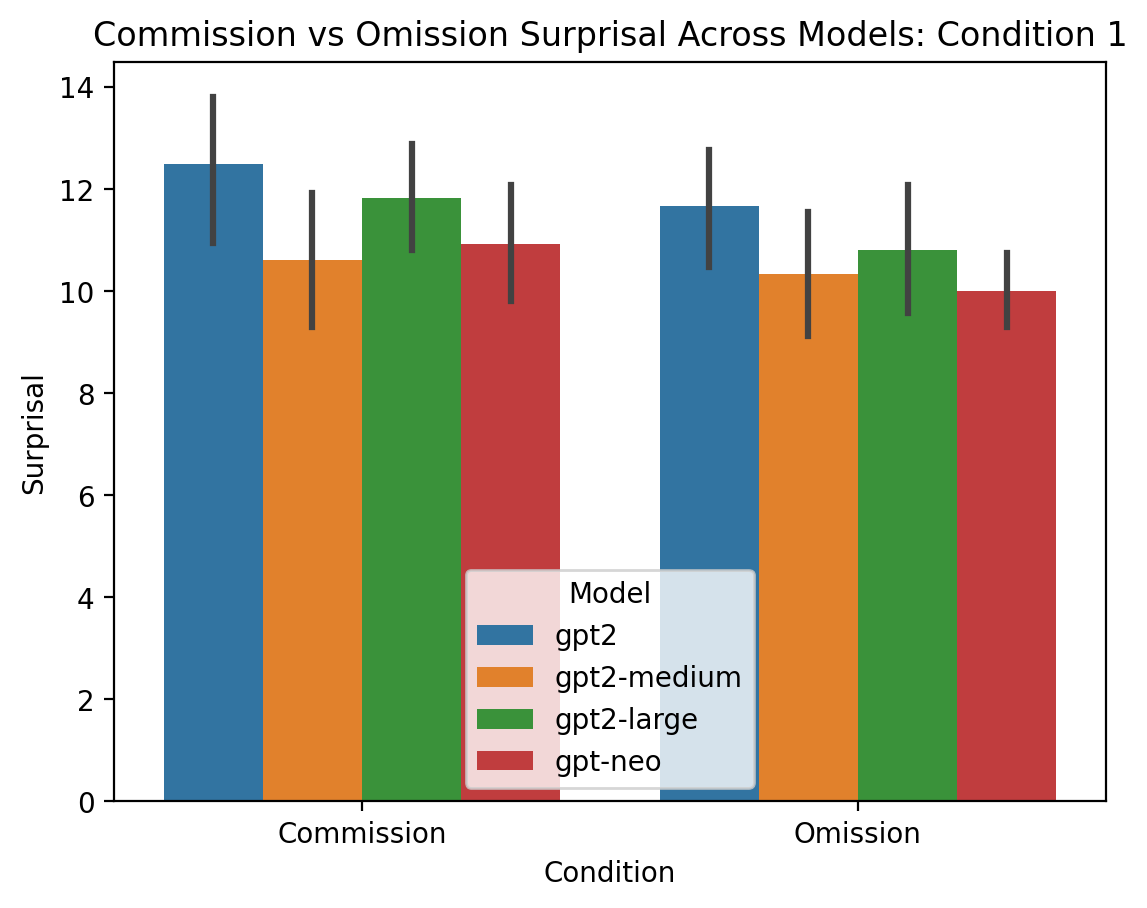

In [ ]:
### Now visualize results!
sns.barplot(data=df_results,
    x="Condition",
    y="Surprisal",
    hue="Model")
plt.title("Commission vs Omission Surprisal Across Models: Condition 1")
plt.ylabel("Surprisal")
plt.show()

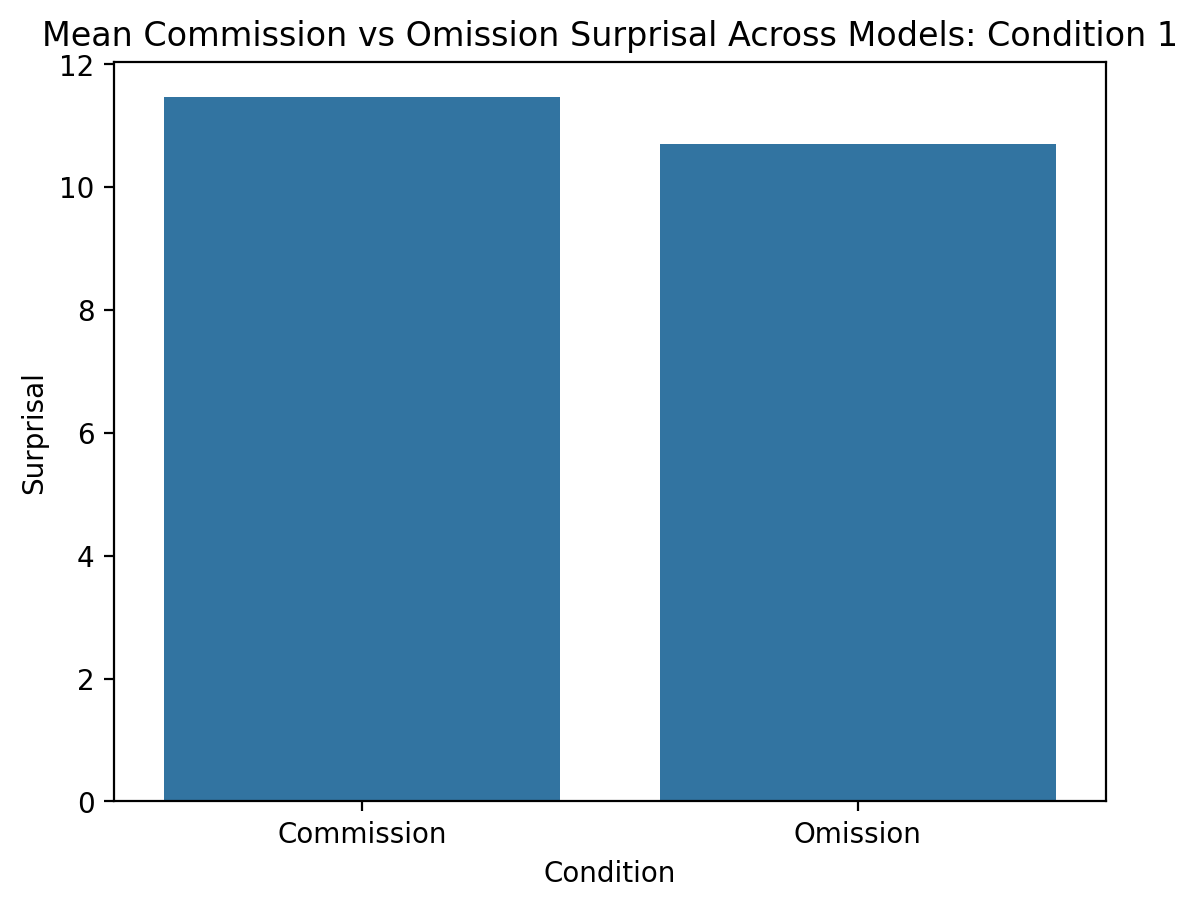

In [ ]:
sns.barplot(data=df_overall,
    x="Condition",
    y="Surprisal")
plt.title("Mean Commission vs Omission Surprisal Across Models: Condition 1")
plt.ylabel("Surprisal")
plt.show()

In [ ]:
#Condition 2: "wrong" target word + intent
stimuli2 = [
    ("Knowing the patient needed oxygen, the nurse intentionally turned off the oxygen supply, which was", " wrong", "Commission", 1),
    ("Knowing the patient needed oxygen, the nurse failed to turn on the oxygen supply, which was", " wrong", "Omission", 1),

    ("Knowing people needed to escape, the landlord intentionally locked the fire exit doors, which was", " wrong", "Commission", 2),
    ("Knowing people needed to escape, the landlord failed to unlock the fire exit doors, which was", " wrong", "Omission", 2),

    ("Knowing the child would overheat, the caregiver intentionally left the child in the hot car, which was", " wrong", "Commission", 3),
    ("Knowing the child would overheat, the caregiver failed to remove the child from the hot car, which was", " wrong", "Omission", 3),

    ("Knowing customers would get sick, the chef intentionally served the spoiled food, which was", " wrong", "Commission", 4),
    ("Knowing customers would get sick, the chef failed to discard the spoiled food, which was", " wrong", "Omission", 4),

    ("Knowing the animal would die, the handler intentionally withheld water from the animal, which was", " wrong", "Commission", 5),
    ("Knowing the animal would die, the handler failed to provide water to the animal, which was", " wrong", "Omission", 5),

    ("Knowing it would poison the water, the factory owner intentionally released toxic waste into the river, which was", " wrong", "Commission", 6),
    ("Knowing it would poison the water, the factory owner failed to prevent toxic waste from entering the river, which was", " wrong", "Omission", 6),

    ("Knowing the patient's heart needed monitoring, the technician intentionally unplugged the heart monitor, which was", " wrong", "Commission", 7),
    ("Knowing the patient's heart needed monitoring, the technician failed to plug in the heart monitor, which was", " wrong", "Omission", 7),

    ("Knowing it would worsen her condition, the pharmacist intentionally gave her the wrong prescription, which was", " wrong", "Commission", 8),
    ("Knowing it would worsen her condition, the pharmacist failed to correct the wrong prescription, which was", " wrong", "Omission", 8),

    ("Knowing it would cause harm, the analyst intentionally leaked the confidential records, which was", " wrong", "Commission", 9),
    ("Knowing it would cause harm, the analyst failed to secure the confidential records, which was", " wrong", "Omission", 9),

    ("Knowing people would get sick, the official intentionally withheld the emergency warning, which was", " wrong", "Commission", 10),
    ("Knowing people would get sick, the official failed to issue the emergency warning, which was", " wrong", "Omission", 10),

    ("Knowing the student would fail, the teacher intentionally erased the student's exam grade, which was", " wrong", "Commission", 11),
    ("Knowing the student would fail, the teacher failed to record the student's exam grade, which was", " wrong", "Omission", 11),

    ("Knowing the house would be vulnerable, the technician intentionally disabled the safety alarm, which was", " wrong", "Commission", 12),
    ("Knowing the house would be vulnerable, the technician failed to activate the safety alarm, which was", " wrong", "Omission", 12),

    ("Knowing pedestrians were crossing, the driver intentionally ran the red light, which was", " wrong", "Commission", 13),
    ("Knowing pedestrians were crossing, the driver failed to stop at the red light, which was", " wrong", "Omission", 13),

    ("Knowing the correct dosage was critical, the doctor intentionally administered the wrong medication, which was", " wrong", "Commission", 14),
    ("Knowing the correct dosage was critical, the doctor failed to correct the medication dosage, which was", " wrong", "Omission", 14)]

In [ ]:
df_stimuli2 = pd.DataFrame(stimuli2, columns = ['Sentence', 'Word', 'Condition', "Pair" ])
df_stimuli2.head(2)

,Sentence,Word,Condition,Pair
0,"Knowing the patient needed oxygen, the nurse i...",wrong,Commission,1
1,"Knowing the patient needed oxygen, the nurse f...",wrong,Omission,1


In [ ]:
results2 = []
for model_name, (model, tokenizer) in models.items():
    for index, row in tqdm(df_stimuli2.iterrows(), total=df_stimuli2.shape[0]):
        prob = next_seq_prob(model, tokenizer, row['Sentence'], row['Word'])
        results2.append({
            'Model': model_name,
            'Word': row['Word'],
            'Sentence': row['Sentence'],
            'Condition': row['Condition'],
            'Pair': row['Pair'],
            'Probability': prob,
            'Surprisal': surprisal(prob)})

100%|██████████| 28/28 [00:05<00:00,  4.94it/s]


In [ ]:
df_results2 = pd.DataFrame(results2)
df_results2.head(2)

,Model,Word,Sentence,Condition,Pair,Probability,Surprisal
0,gpt2,wrong,"Knowing the patient needed oxygen, the nurse i...",Commission,1,0.000197,12.308231
1,gpt2,wrong,"Knowing the patient needed oxygen, the nurse f...",Omission,1,0.000284,11.780825


In [ ]:
df_grouped2 = df_results2.groupby(["Model", "Condition"])["Surprisal"].mean().reset_index()
df_grouped2.head(2)

,Model,Condition,Surprisal
0,gpt-neo,Commission,9.801867
1,gpt-neo,Omission,9.791235


In [ ]:
df_overall2 = df_results2.groupby("Condition")["Surprisal"].mean().reset_index()
df_overall2

,Condition,Surprisal
0,Commission,10.871543
1,Omission,10.787443


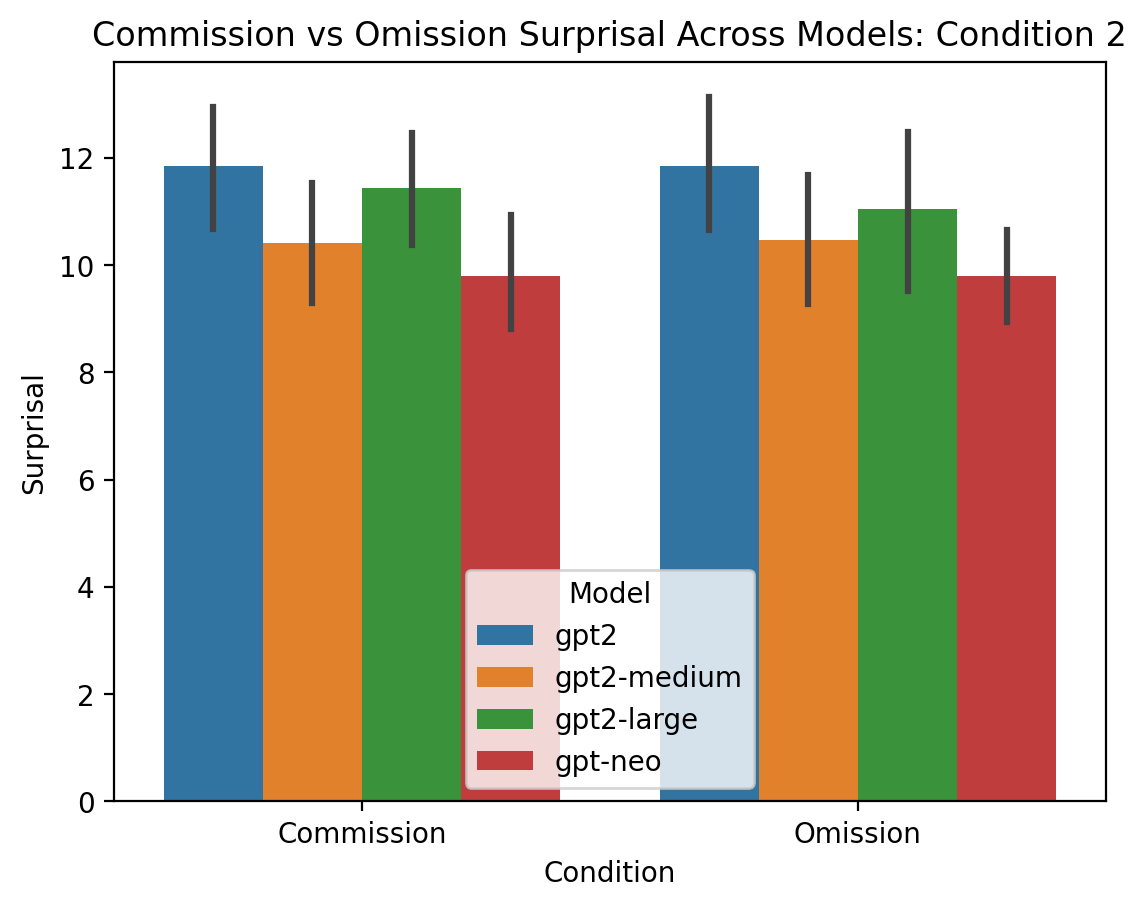

In [ ]:
sns.barplot(data=df_results2,
    x="Condition",
    y="Surprisal",
    hue="Model")
plt.title("Commission vs Omission Surprisal Across Models: Condition 2")
plt.ylabel("Surprisal")
plt.show()

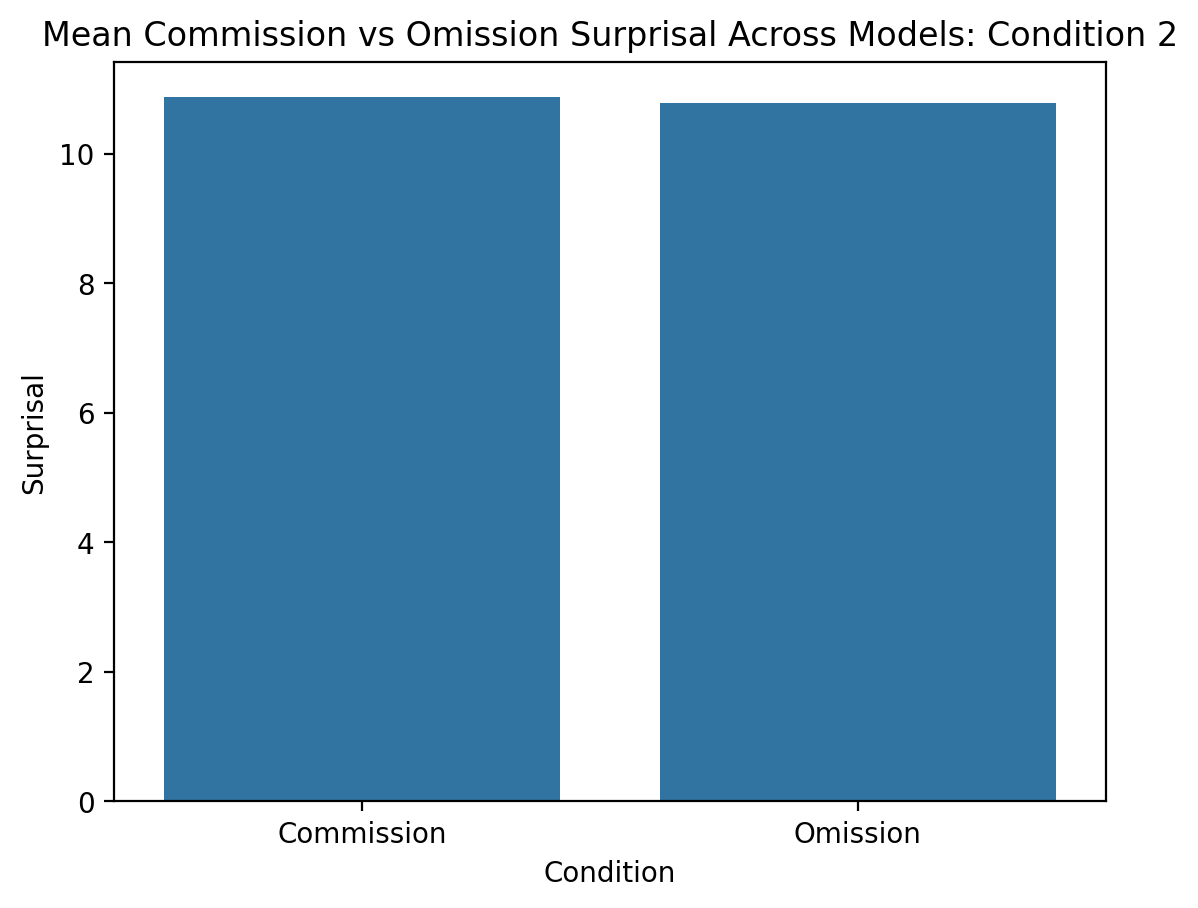

In [ ]:
sns.barplot(data=df_overall2,
    x="Condition",
    y="Surprisal")
plt.title("Mean Commission vs Omission Surprisal Across Models: Condition 2")
plt.ylabel("Surprisal")
plt.show()

In [ ]:
#Condition 3: "acceptable" target word
stimuli3 = [
    ("Knowing the patient needed oxygen, the nurse turned off the oxygen supply, which was", " acceptable", "Commission", 1),
    ("Knowing the patient needed oxygen, the nurse did not turn on the oxygen supply, which was", " acceptable", "Omission", 1),

    ("Knowing people needed to escape, the landlord locked the fire exit doors, which was", " acceptable", "Commission", 2),
    ("Knowing people needed to escape, the landlord did not unlock the fire exit doors, which was", " acceptable", "Omission", 2),

    ("Knowing the child would overheat, the caregiver left the child in the hot car, which was", " acceptable", "Commission", 3),
    ("Knowing the child would overheat, the caregiver did not remove the child from the hot car, which was", " acceptable", "Omission", 3),

    ("Knowing customers would get sick, the chef served the spoiled food, which was", " acceptable", "Commission", 4),
    ("Knowing customers would get sick, the chef did not discard the spoiled food, which was", " acceptable", "Omission", 4),

    ("Knowing the animal would die, the handler withheld water from the animal, which was", " acceptable", "Commission", 5),
    ("Knowing the animal would die, the handler did not provide water to the animal, which was", " acceptable", "Omission", 5),

    ("Knowing it would poison the water, the factory owner released toxic waste into the river, which was", " acceptable", "Commission", 6),
    ("Knowing it would poison the water, the factory owner did not prevent toxic waste from entering the river, which was", " acceptable", "Omission", 6),

    ("Knowing the patient's heart needed monitoring, the technician unplugged the heart monitor, which was", " acceptable", "Commission", 7),
    ("Knowing the patient's heart needed monitoring, the technician did not plug in the heart monitor, which was", " acceptable", "Omission", 7),

    ("Knowing it would worsen her condition, the pharmacist gave her the wrong prescription, which was", " acceptable", "Commission", 8),
    ("Knowing it would worsen her condition, the pharmacist did not correct the wrong prescription, which was", " acceptable", "Omission", 8),

    ("Knowing it would cause harm, the analyst leaked the confidential records, which was", " acceptable", "Commission", 9),
    ("Knowing it would cause harm, the analyst did not secure the confidential records, which was", " acceptable", "Omission", 9),

    ("Knowing people would get sick, the official withheld the emergency warning, which was", " acceptable", "Commission", 10),
    ("Knowing people would get sick, the official did not issue the emergency warning, which was", " acceptable", "Omission", 10),

    ("Knowing the student would fail, the teacher erased the student's exam grade, which was", " acceptable", "Commission", 11),
    ("Knowing the student would fail, the teacher did not record the student's exam grade, which was", " acceptable", "Omission", 11),

    ("Knowing the house would be vulnerable, the technician disabled the safety alarm, which was", " acceptable", "Commission", 12),
    ("Knowing the house would be vulnerable, the technician did not activate the safety alarm, which was", " acceptable", "Omission", 12),

    ("Knowing pedestrians were crossing, the driver ran the red light, which was", " acceptable", "Commission", 13),
    ("Knowing pedestrians were crossing, the driver did not stop at the red light, which was", " acceptable", "Omission", 13),

    ("Knowing the correct dosage was critical, the doctor administered the wrong medication, which was", " acceptable", "Commission", 14),
    ("Knowing the correct dosage was critical, the doctor did not correct the medication dosage, which was", " acceptable", "Omission", 14)]

In [ ]:
df_stimuli3 = pd.DataFrame(stimuli3, columns = ['Sentence', 'Word', 'Condition', "Pair" ])
df_stimuli3.head(2)

,Sentence,Word,Condition,Pair
0,"Knowing the patient needed oxygen, the nurse t...",acceptable,Commission,1
1,"Knowing the patient needed oxygen, the nurse d...",acceptable,Omission,1


In [ ]:
results3 = []
for model_name, (model, tokenizer) in models.items():
    for index, row in tqdm(df_stimuli3.iterrows(), total=df_stimuli3.shape[0]):
        prob = next_seq_prob(model, tokenizer, row['Sentence'], row['Word'])
        results3.append({
            'Model': model_name,
            'Word': row['Word'],
            'Sentence': row['Sentence'],
            'Condition': row['Condition'],
            'Pair': row['Pair'],
            'Probability': prob,
            'Surprisal': surprisal(prob)})

100%|██████████| 28/28 [00:04<00:00,  5.83it/s]


In [ ]:
df_results3 = pd.DataFrame(results3)
df_results3.head(2)

,Model,Word,Sentence,Condition,Pair,Probability,Surprisal
0,gpt2,acceptable,"Knowing the patient needed oxygen, the nurse t...",Commission,1,0.000103,13.250729
1,gpt2,acceptable,"Knowing the patient needed oxygen, the nurse d...",Omission,1,0.000349,11.485292


In [ ]:
df_grouped3 = df_results3.groupby(["Model", "Condition"])["Surprisal"].mean().reset_index()
df_grouped3.head(2)

,Model,Condition,Surprisal
0,gpt-neo,Commission,13.443193
1,gpt-neo,Omission,11.928958


In [ ]:
df_overall3 = df_results3.groupby("Condition")["Surprisal"].mean().reset_index()
df_overall3

,Condition,Surprisal
0,Commission,14.055806
1,Omission,12.618818


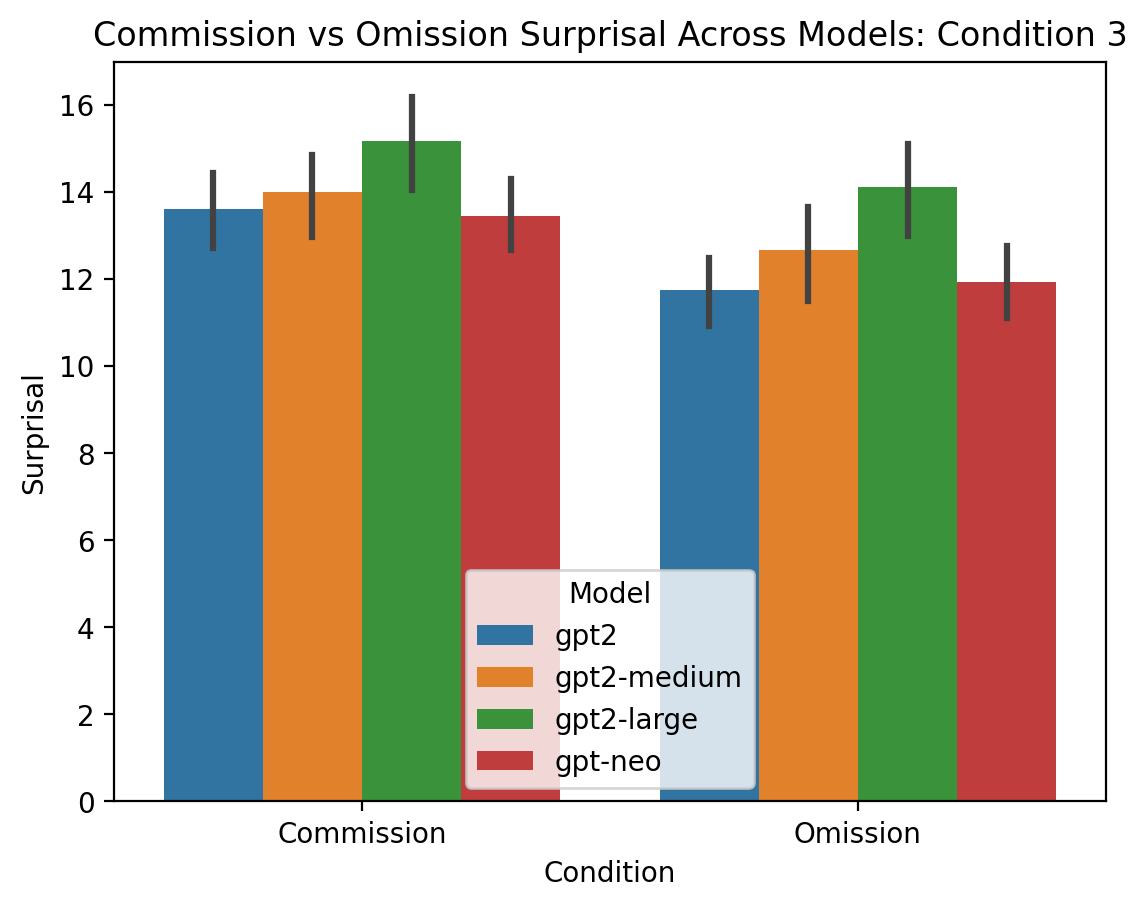

In [ ]:
sns.barplot(data=df_results3,
    x="Condition",
    y="Surprisal",
    hue="Model")
plt.title("Commission vs Omission Surprisal Across Models: Condition 3")
plt.ylabel("Surprisal")
plt.show()

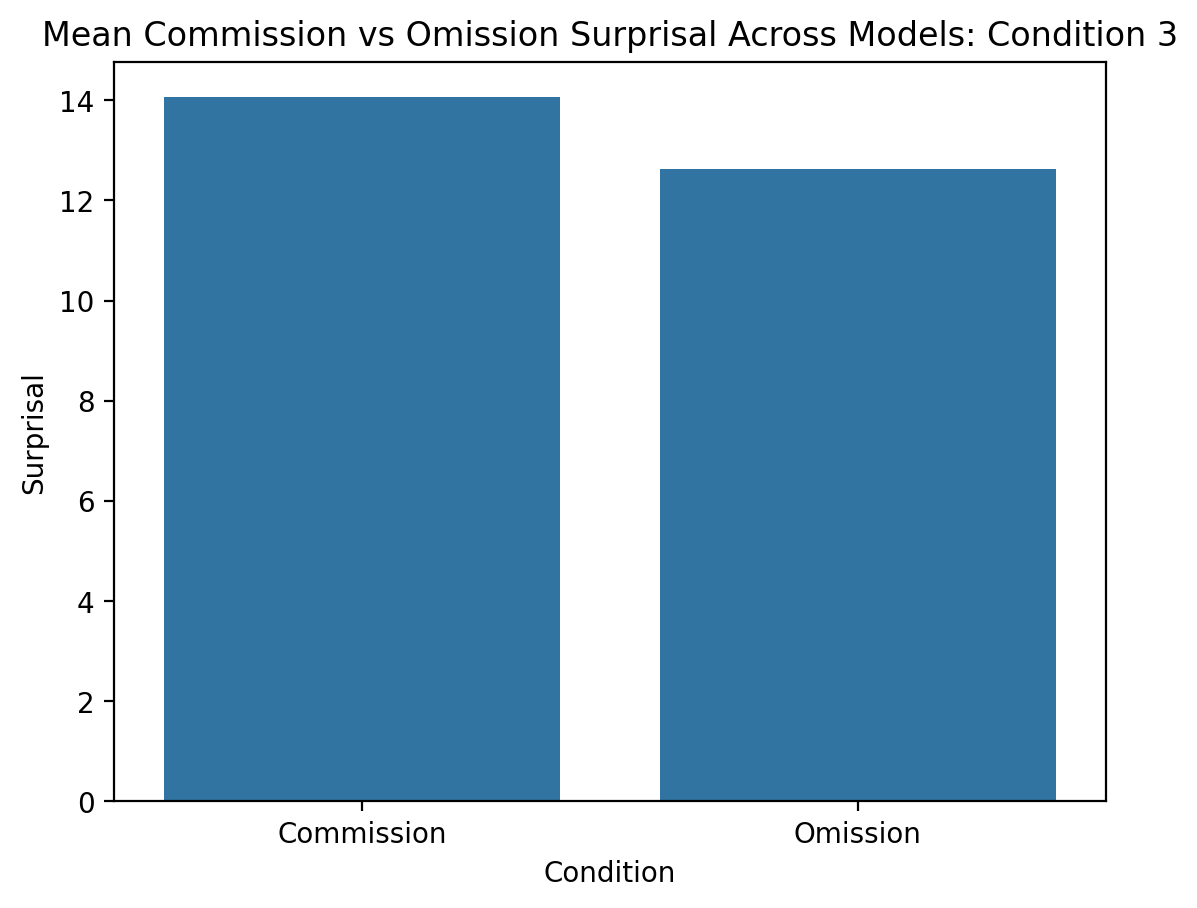

In [ ]:
sns.barplot(data=df_overall3,
    x="Condition",
    y="Surprisal")
plt.title("Mean Commission vs Omission Surprisal Across Models: Condition 3")
plt.ylabel("Surprisal")
plt.show()

In [ ]:
#Condition 4: "acceptable" target word + intent
stimuli4 = [
    ("Knowing the patient needed oxygen, the nurse intentionally turned off the oxygen supply, which was", " acceptable", "Commission", 1),
    ("Knowing the patient needed oxygen, the nurse failed to turn on the oxygen supply, which was", " acceptable", "Omission", 1),

    ("Knowing people needed to escape, the landlord intentionally locked the fire exit doors, which was", " acceptable", "Commission", 2),
    ("Knowing people needed to escape, the landlord failed to unlock the fire exit doors, which was", " acceptable", "Omission", 2),

    ("Knowing the child would overheat, the caregiver intentionally left the child in the hot car, which was", " acceptable", "Commission", 3),
    ("Knowing the child would overheat, the caregiver failed to remove the child from the hot car, which was", " acceptable", "Omission", 3),

    ("Knowing customers would get sick, the chef intentionally served the spoiled food, which was", " acceptable", "Commission", 4),
    ("Knowing customers would get sick, the chef failed to discard the spoiled food, which was", " acceptable", "Omission", 4),

    ("Knowing the animal would die, the handler intentionally withheld water from the animal, which was", " acceptable", "Commission", 5),
    ("Knowing the animal would die, the handler failed to provide water to the animal, which was", " acceptable", "Omission", 5),

    ("Knowing it would poison the water, the factory owner intentionally released toxic waste into the river, which was", " acceptable", "Commission", 6),
    ("Knowing it would poison the water, the factory owner failed to prevent toxic waste from entering the river, which was", " acceptable", "Omission", 6),

    ("Knowing the patient's heart needed monitoring, the technician intentionally unplugged the heart monitor, which was", " acceptable", "Commission", 7),
    ("Knowing the patient's heart needed monitoring, the technician failed to plug in the heart monitor, which was", " acceptable", "Omission", 7),

    ("Knowing it would worsen her condition, the pharmacist intentionally gave her the wrong prescription, which was", " acceptable", "Commission", 8),
    ("Knowing it would worsen her condition, the pharmacist failed to correct the wrong prescription, which was", " acceptable", "Omission", 8),

    ("Knowing it would cause harm, the analyst intentionally leaked the confidential records, which was", " acceptable", "Commission", 9),
    ("Knowing it would cause harm, the analyst failed to secure the confidential records, which was", " acceptable", "Omission", 9),

    ("Knowing people would get sick, the official intentionally withheld the emergency warning, which was", " acceptable", "Commission", 10),
    ("Knowing people would get sick, the official failed to issue the emergency warning, which was", " acceptable", "Omission", 10),

    ("Knowing the student would fail, the teacher intentionally erased the student's exam grade, which was", " acceptable", "Commission", 11),
    ("Knowing the student would fail, the teacher failed to record the student's exam grade, which was", " acceptable", "Omission", 11),

    ("Knowing the house would be vulnerable, the technician intentionally disabled the safety alarm, which was", " acceptable", "Commission", 12),
    ("Knowing the house would be vulnerable, the technician failed to activate the safety alarm, which was", " acceptable", "Omission", 12),

    ("Knowing pedestrians were crossing, the driver intentionally ran the red light, which was", " acceptable", "Commission", 13),
    ("Knowing pedestrians were crossing, the driver failed to stop at the red light, which was", " acceptable", "Omission", 13),

    ("Knowing the correct dosage was critical, the doctor intentionally administered the wrong medication, which was", " acceptable", "Commission", 14),
    ("Knowing the correct dosage was critical, the doctor failed to correct the medication dosage, which was", " acceptable", "Omission", 14),]

In [ ]:
df_stimuli4 = pd.DataFrame(stimuli4, columns = ['Sentence', 'Word', 'Condition', "Pair" ])
df_stimuli4.head(2)

,Sentence,Word,Condition,Pair
0,"Knowing the patient needed oxygen, the nurse i...",acceptable,Commission,1
1,"Knowing the patient needed oxygen, the nurse f...",acceptable,Omission,1


In [ ]:
results4 = []
for model_name, (model, tokenizer) in models.items():
    for index, row in tqdm(df_stimuli4.iterrows(), total=df_stimuli4.shape[0]):
        prob = next_seq_prob(model, tokenizer, row['Sentence'], row['Word'])
        results4.append({
            'Model': model_name,
            'Word': row['Word'],
            'Sentence': row['Sentence'],
            'Condition': row['Condition'],
            'Pair': row['Pair'],
            'Probability': prob,
            'Surprisal': surprisal(prob)})

100%|██████████| 28/28 [00:04<00:00,  5.88it/s]


In [ ]:
df_results4 = pd.DataFrame(results4)
df_results4.head(2)

,Model,Word,Sentence,Condition,Pair,Probability,Surprisal
0,gpt2,acceptable,"Knowing the patient needed oxygen, the nurse i...",Commission,1,0.000109,13.161552
1,gpt2,acceptable,"Knowing the patient needed oxygen, the nurse f...",Omission,1,0.000103,13.245864


In [ ]:
df_grouped4 = df_results4.groupby(["Model", "Condition"])["Surprisal"].mean().reset_index()
df_grouped4.head(2)

,Model,Condition,Surprisal
0,gpt-neo,Commission,13.22362
1,gpt-neo,Omission,13.32380


In [ ]:
df_overall4 = df_results4.groupby("Condition")["Surprisal"].mean().reset_index()
df_overall4

,Condition,Surprisal
0,Commission,13.922609
1,Omission,13.995462


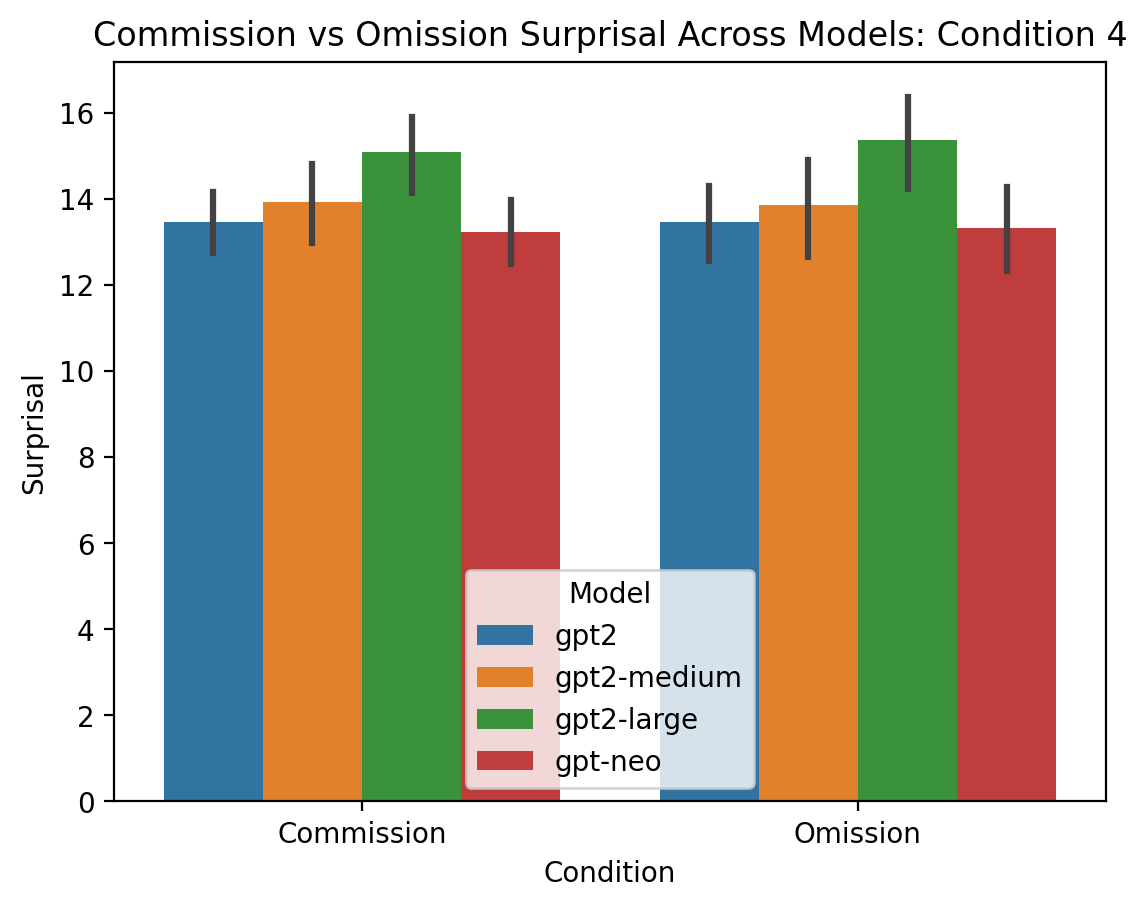

In [ ]:
sns.barplot(data=df_results4,
    x="Condition",
    y="Surprisal",
    hue="Model")
plt.title("Commission vs Omission Surprisal Across Models: Condition 4")
plt.ylabel("Surprisal")
plt.show()

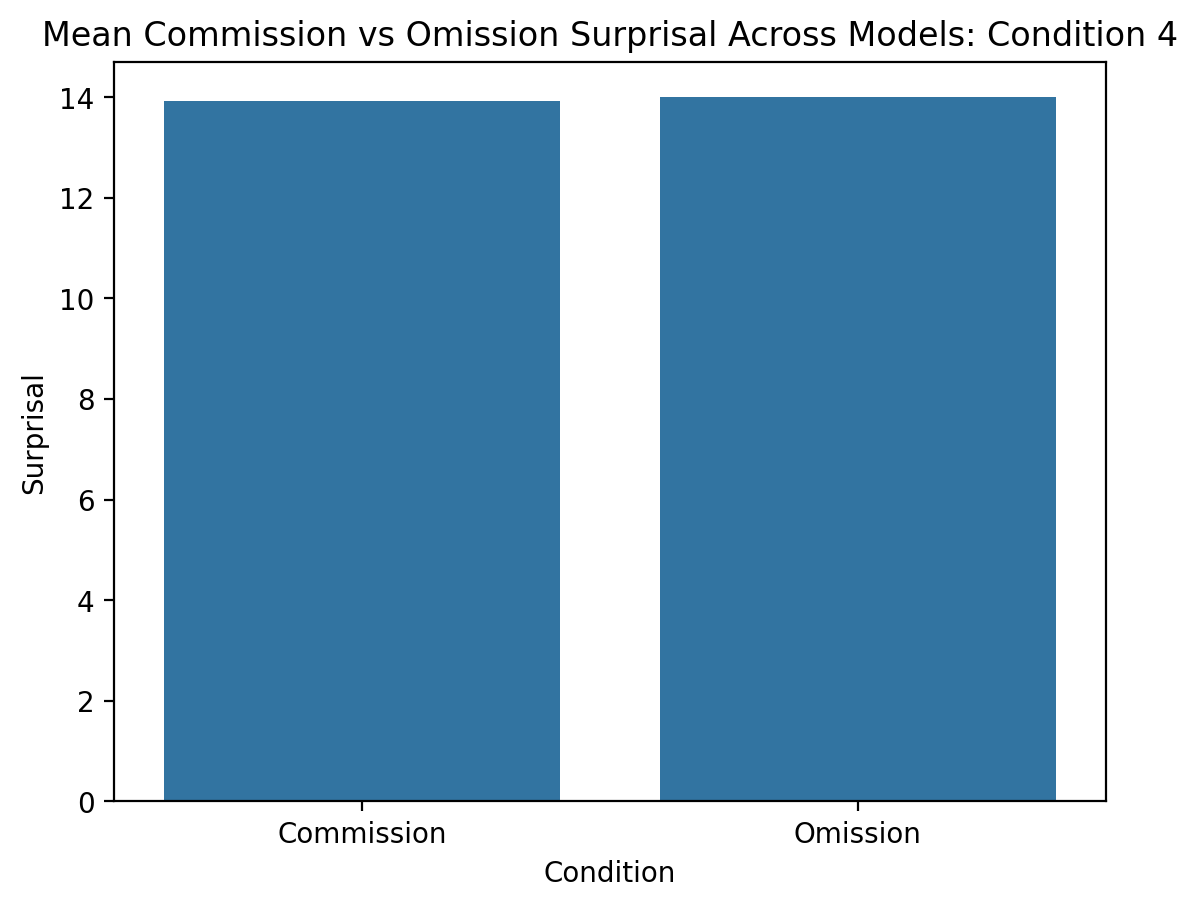

In [ ]:
sns.barplot(data=df_overall4,
    x="Condition",
    y="Surprisal")
plt.title("Mean Commission vs Omission Surprisal Across Models: Condition 4")
plt.ylabel("Surprisal")
plt.show()

In [ ]:
#Finding mean surprisal for commission and omission across stimuli
df_results ["StimulusType"] = "Wrong"
df_results2 ["StimulusType"] = "Wrong + Intent"
df_results3 ["StimulusType"] = "Acceptable"
df_results4 ["StimulusType"] = "Acceptable + Intent"

In [ ]:
df_all = pd.concat ([df_results, df_results2, df_results3, df_results4])

In [ ]:
df_summary_all = (df_all.groupby(["StimulusType", "Model","Condition"])["Surprisal"]
                  .mean()
                  .reset_index())
df_summary_all.head(2)

,StimulusType,Model,Condition,Surprisal
0,Acceptable,gpt-neo,Commission,13.443193
1,Acceptable,gpt-neo,Omission,11.928958


In [ ]:
df_table_all = df_summary_all.pivot_table(index = ["StimulusType", "Model"],
                                          columns = "Condition",
                                          values = "Surprisal").reset_index()
df_table_all.head()


Condition,StimulusType,Model,Commission,Omission
0,Acceptable,gpt-neo,13.443193,11.928958
1,Acceptable,gpt2,13.599409,11.753455
2,Acceptable,gpt2-large,15.172259,14.118185
3,Acceptable,gpt2-medium,14.008364,12.674673
4,Acceptable + Intent,gpt-neo,13.223620,13.323800


In [ ]:
#Add commission - omission difference column
df_table_all["Difference"] = df_table_all["Commission"] - df_table_all["Omission"]
df_table_all.head()

Condition,StimulusType,Model,Commission,Omission,Difference
0,Acceptable,gpt-neo,13.443193,11.928958,1.514236
1,Acceptable,gpt2,13.599409,11.753455,1.845954
2,Acceptable,gpt2-large,15.172259,14.118185,1.054074
3,Acceptable,gpt2-medium,14.008364,12.674673,1.333690
4,Acceptable + Intent,gpt-neo,13.223620,13.323800,-0.100181


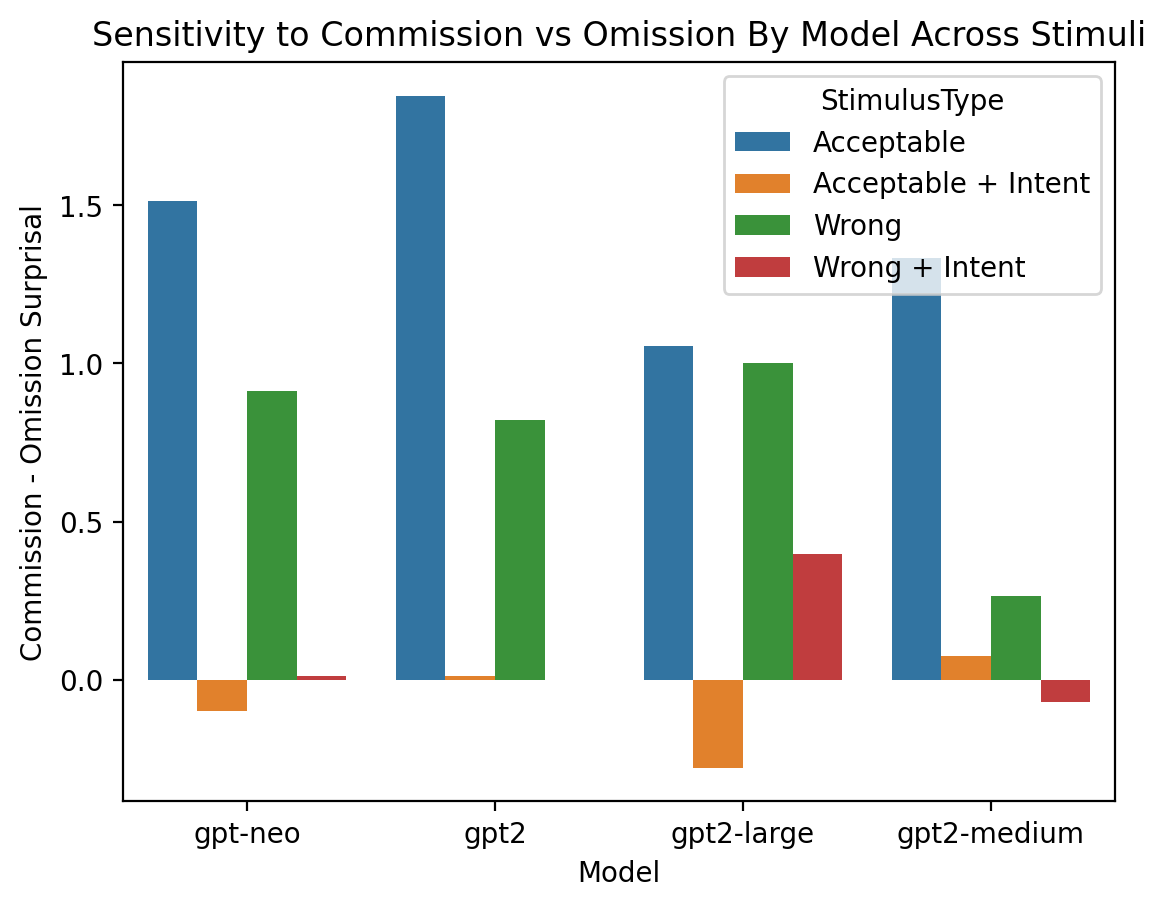

In [ ]:
#Figure1: Do LLMs differ in how strongly they distinguish commission from omission?
#positive difference means commision is higher for that model
#negative difference means omission is higher for that model
sns.barplot(data=df_table_all,
    x="Model",
    y="Difference",
    hue="StimulusType")
plt.title("Sensitivity to Commission vs Omission By Model Across Stimuli")
plt.ylabel("Commission - Omission Surprisal")
plt.show()

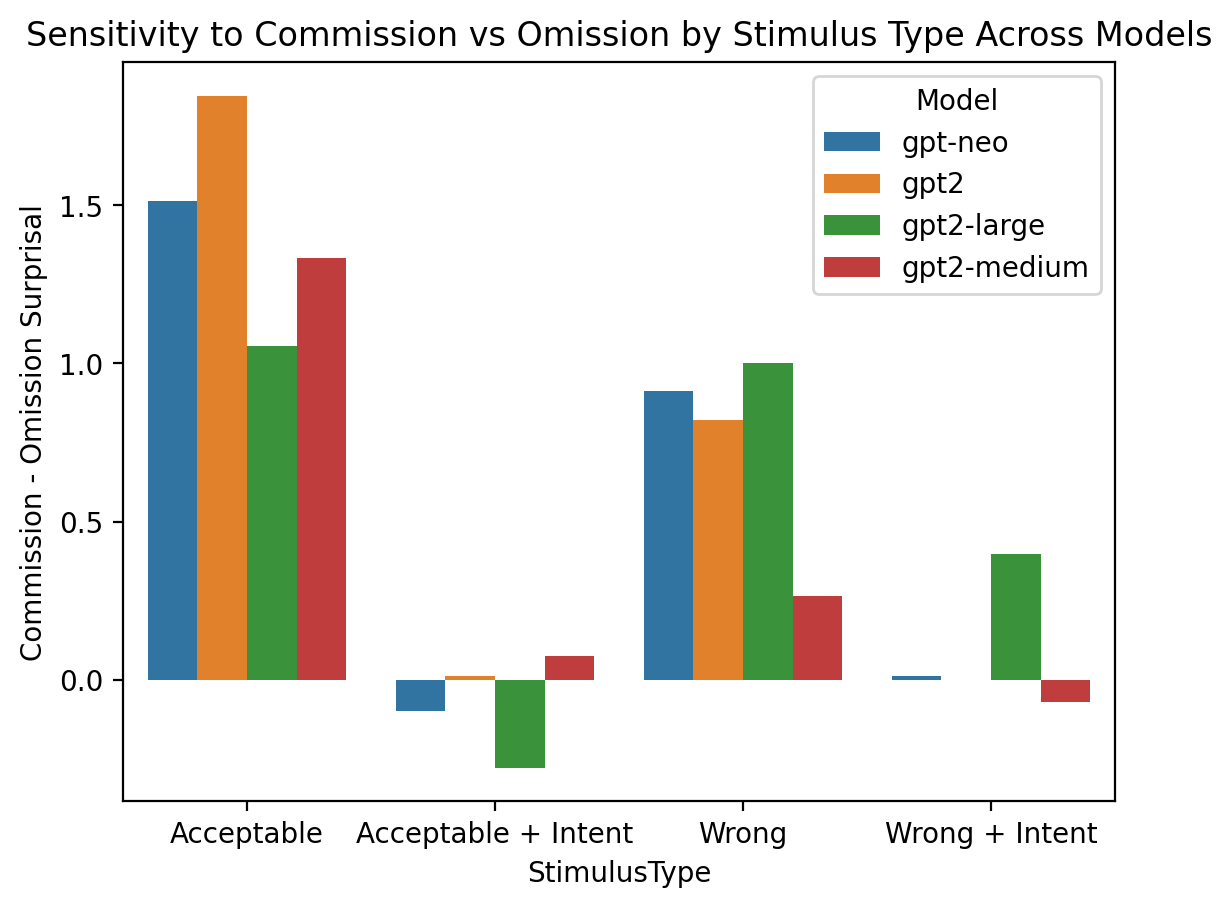

In [ ]:
#Figure2: Does linguistic framing change the difference between commission and omission across models?
#positive difference means commision is higher for that stimulus
#negative difference means omission is higher for that stimulus
sns.barplot(data=df_table_all,
    x="StimulusType",
    y="Difference",
    hue="Model")
plt.title("Sensitivity to Commission vs Omission by Stimulus Type Across Models")
plt.ylabel("Commission - Omission Surprisal")
plt.show()

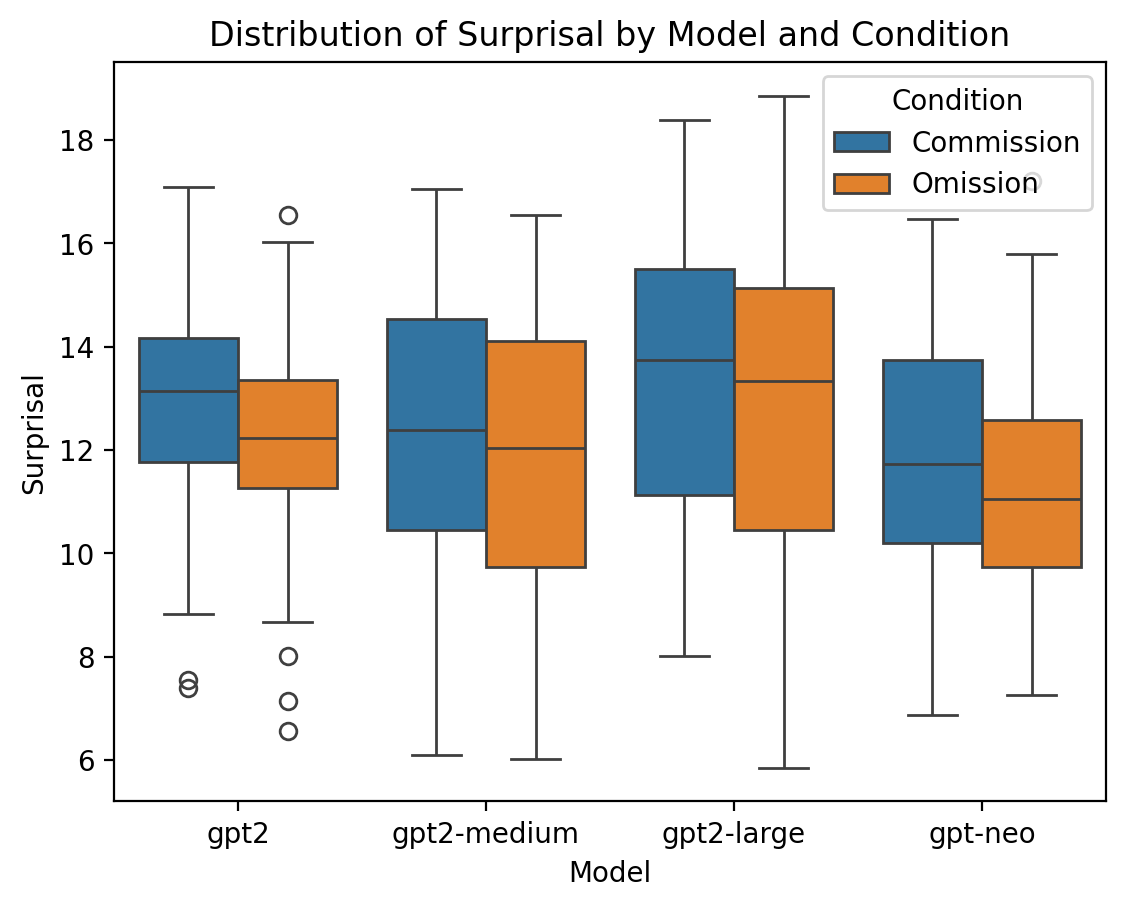

In [ ]:
#Figure3: What is mean surprisal of models across stimuli? How much variability exists within each model?
sns.boxplot(data=df_all,
    x="Model",
    y="Surprisal",
    hue="Condition")
plt.title("Distribution of Surprisal by Model and Condition")
plt.show()

**Results**

Surprisal patterns were consistent across three of the four conditions. Across models, surprisal for “wrong” was lower after omissions than after commissions, indicating that LLMs expected the word “wrong” more strongly following omissions than commissions. For the first baseline “wrong” condition, the average surprisal across models was 11.46 for commission and 10.71 for omission.

However, as seen in Figure 2, the fourth condition of “acceptable + intent" showed a small reversal of this pattern. Omission had an average surprisal score of 13.99 and commission had an average surprisal score of 13.92 across the models. This suggests that LLM moral expectations are highly sensitive to how the sentence is worded and may shift depending on subtle word choices or sentence structure. Based on Figure 1, the only two models that had a higher omission that commission surprisal were the GPT Neo and GPT-2 Large models, which have the most parameters and are the newer models compared to the other two.

Overall, for the conditions with “wrong”, the result is the opposite of classic human omission bias, where commissions are judged more harshly. Instead, LLMs showed a reverse omission pattern, in which moral disaproval was more expected after omissions than actions. Because surprisal measures prediction rather than judgment, these results reflect statistical language-based moral expectations, not what the model “believes” or would explicitly judge. Lastly, no formal statistical significance testing was performed, so observed differences serve as descriptive information rather than any causal evidence.

**Interpretation/Discussion**

Human research has shown that people judge harmful commissions as more morally wrong than equivalent omissions (Spranca et al., 1991; Baron & Ritov, 2004; Jamison et al. 2020). In contrast, the current results demonstrate that LLMs predict the word “wrong” as more expected following omissions than commissions. This reversal suggests a disconnect between human moral cognition and LLM moral language prediction.

One plausible explanation is that the models learned statistical co-occurrence patterns from their training data. Phrases such as “failed to X, which was wrong” or “did not X, which was wrong” may occur more frequently in legal, medical, or news text than active commission statements paired with moral disapproval. As a result, the models may learn that omission-style phrasing is statistically associated with moral disapproval, even though humans psychologically judge commissions as more immoral.

Furthermore, comission is higher than omission surprisal on average in the fourth condition and for one model in the second condition, which are the two "target word + intent" conditions. This suggests that LLM moral expectations are highly sensitive to sentence wording or structure rather than actually viewing a commission scenario as more “acceptable” or "wrong" than an omission. When lexical cues differ slightly, the statistical patterns of the moral language prediction may shift. This supports that LLM moral behavior in this task is driven primarily by statistical patterns in text rather than human-like moral principles.

Together, these findings suggest that while LLMs learn patterns in moral language, they do not reproduce the same commission-omission cognitive distinction seen in human moral judgment.

**Limitations**

The first limitation of this study is how surprisal is sensitive to specific lexical and syntactic structure, meaning that subtle phrasing differences may influence the results independently of moral reasoning. While I tried to control for this by holding sentence structure as constant as possible across pairs, some lexical variation can occur when expressing action vs. inaction, such as “turned off” vs. “did not turn on”, and could influence the surprisal score.

Second, moral evaluation was operationalized using only single word moral-labels such as “wrong” and “acceptable”, which captures word-level moral expectations rather than deeper moral reasoning, inferences about intent, or explicit moral choice.

Third, LLMs may have been exposed during training to academic discussions of omission bias or to legal and medical reporting that disproportionately emphasize failures to act instead of action words leading to a lower omission surprisal score.

Additionally, only smaller models that had transformers available on Hugging Face were used for this study. They cannot represent all large language models. This is evident by how the two largest models, GPT-Neo and GPT-2 Large, were the only ones that mirrored human moral judgement in the fourth condition when their omission surprisal was higher than their commission surprisal. More modern models with larger parameters may produce a different surprisal result.

Lastly, it is difficult to directly compare human psychology test to operationalized LLM tests. The human psychology tests were typically done on a rating scale while this study used a binary outcome of “wrong” or “acceptable” to measure expectations with surprisal. This difference in measurement makes direct quantitative comparison challenging but allows for further questions about implicit moral associations in language models. Also, the human studies provided more context and background to each scenarios, whereas the minimal pairs in this study were short sentences with little context. Additionally, human omission bias is strongly influenced by judgments of intent and responsibility, but the surprisal method measures prediction rather than explicit reasoning about intent or causation. The models are predicting word likelihoods based on distributional patterns in text.

**Conclusion**

This study tested whether large language models exhibit human omission bias using surprisal as a measure of implicit moral expectation. Across four models and four stimulus conditions, LLMs did not reproduce the human omission bias. Instead, they generally predicted moral disaproval as more expected following omissions than commissions, a reversed pattern compared to human moral judgment.

These results suggest that LLMs appear to rely on statistical regularities in moral language rather than structured moral principles. Although LLMs capture many surface-level moral patterns in text, they do not consistently show the same moral weighting of actions versus inactions than in human moral cognition. Instead, they appear to highlight a different relationship between action type and moral condemnation in language. This finding points to both the potential and the limits of using LLMs as cognitive models of moral reasoning, especially as such models are increasingly deployed in medical, legal, and public policy domains. Future work could explore explicit judgment tasks, multi-word moral evaluations, and behavioral choice patterns to more directly compare LLM and human moral cognition.
